In [1]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

# Load the dataset
dataset = load_breast_cancer()

# Create the feature DataFrame
X = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

# Create the target Series
y = pd.Series(
    dataset.target,
    name="diagnosis"
)

# Combine features and target for initial inspection
df = X.copy()
df["diagnosis"] = y.map({
    0: "malignant",
    1: "benign"
})

print("Dataset shape:", df.shape)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (569, 31)
Feature shape: (569, 30)
Target shape: (569,)


In [2]:
display(df.head())

df.info()

print("\nMissing values:")
print(df.isna().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDiagnosis counts:")
print(df["diagnosis"].value_counts())

print("\nDiagnosis proportions:")
print(df["diagnosis"].value_counts(normalize=True).round(3))

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [3]:
# Descriptive statistics for the 30 numerical features
display(X.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


In [4]:
# Inspect the features with the largest standard deviations
feature_summary = X.describe().T

display(
    feature_summary[
        ["mean", "std", "min", "25%", "50%", "75%", "max"]
    ].sort_values("std", ascending=False)
)

,mean,std,min,25%,50%,75%,max
worst area,880.583128,569.356993,185.200000,515.300000,686.500000,1084.000000,4254.00000
mean area,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
area error,40.337079,45.491006,6.802000,17.850000,24.530000,45.190000,542.20000
worst perimeter,107.261213,33.602542,50.410000,84.110000,97.660000,125.400000,251.20000
mean perimeter,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
worst texture,25.677223,6.146258,12.020000,21.080000,25.410000,29.720000,49.54000
worst radius,16.269190,4.833242,7.930000,13.010000,14.970000,18.790000,36.04000
mean texture,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean radius,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
perimeter error,2.866059,2.021855,0.757000,1.606000,2.287000,3.357000,21.98000


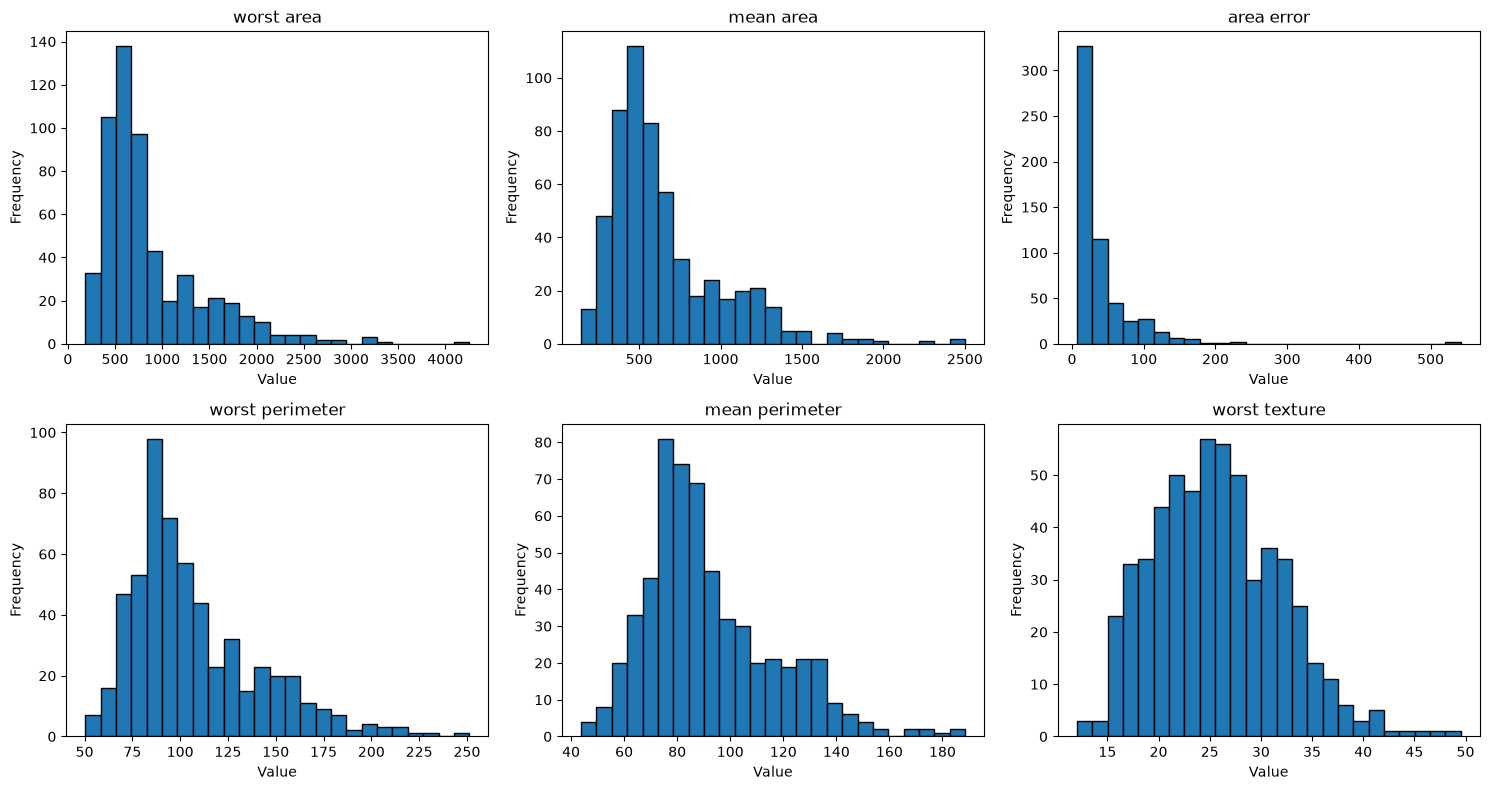

In [5]:
import matplotlib.pyplot as plt

# Plot distributions for the features with the largest standard deviations
top_features = (
    X.std()
    .sort_values(ascending=False)
    .head(6)
    .index
)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for feature, ax in zip(top_features, axes.flat):
    ax.hist(X[feature], bins=25, edgecolor="black")
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

C:\Users\pc\AppData\Local\Temp\ipykernel_4980\2006452574.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(X[feature], vert=True)
C:\Users\pc\AppData\Local\Temp\ipykernel_4980\2006452574.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(X[feature], vert=True)
C:\Users\pc\AppData\Local\Temp\ipykernel_4980\2006452574.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(X[feature], vert=True)
C:\Users\pc\AppData\Local\Temp\ipykernel_4980\2006452574.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot

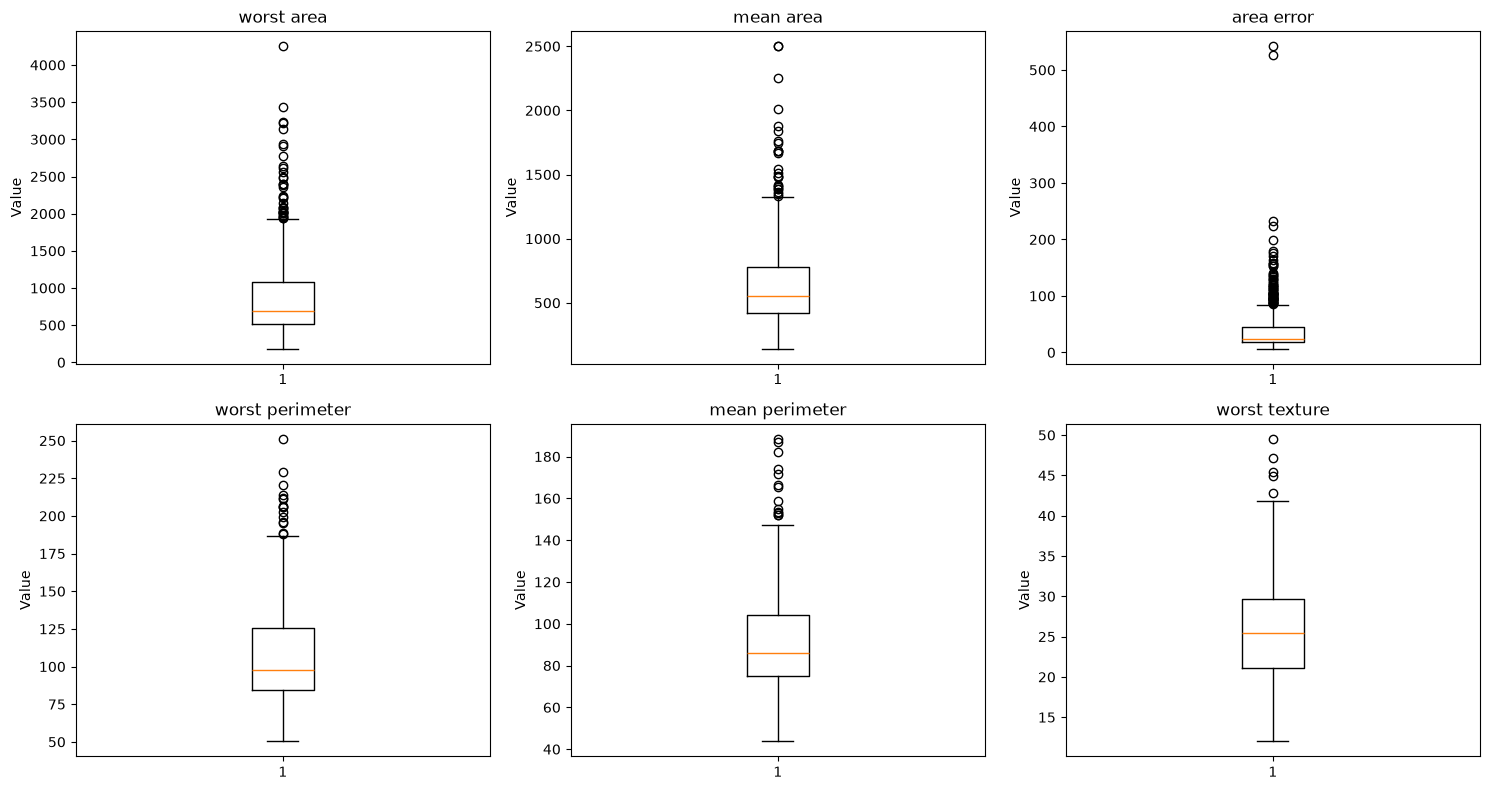

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for feature, ax in zip(top_features, axes.flat):
    ax.boxplot(X[feature], vert=True)
    ax.set_title(feature)
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()

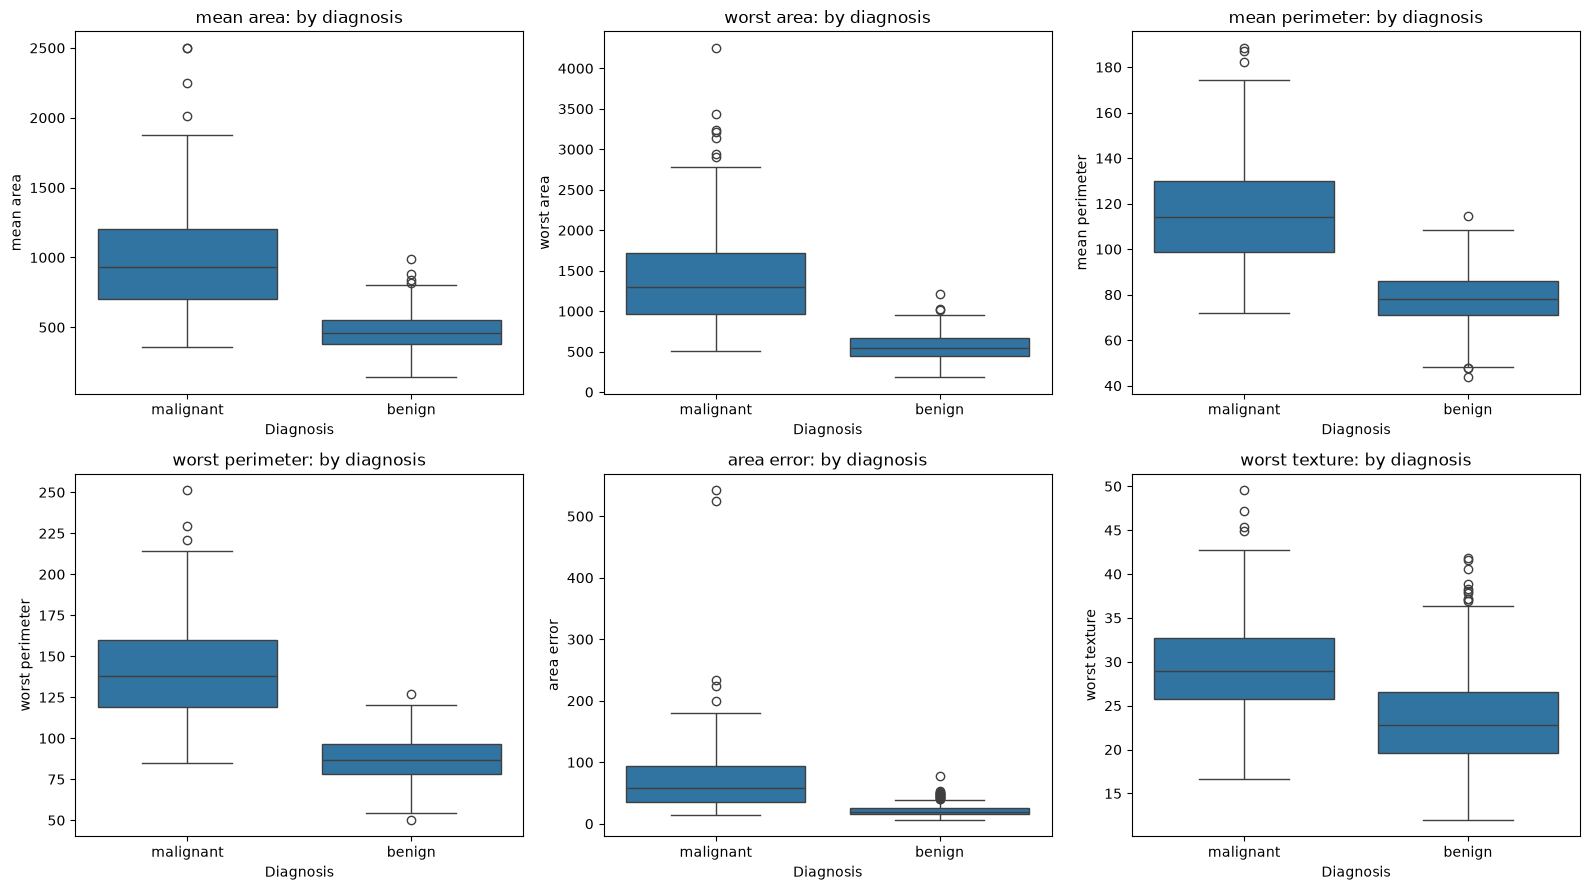

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

selected_features = [
    "mean area",
    "worst area",
    "mean perimeter",
    "worst perimeter",
    "area error",
    "worst texture",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for feature, ax in zip(selected_features, axes.flat):
    sns.boxplot(
        data=df,
        x="diagnosis",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature}: by diagnosis")
    ax.set_xlabel("Diagnosis")

plt.tight_layout()
plt.show()


In [8]:
#%pip install statsmodels

In [9]:

import pandas as pd
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

selected_features = [
    "mean area",
    "worst area",
    "mean perimeter",
    "worst perimeter",
    "area error",
    "worst texture",
]

results = []

for feature in selected_features:
    malignant = df.loc[
        df["diagnosis"] == "malignant", feature
    ]
    benign = df.loc[
        df["diagnosis"] == "benign", feature
    ]

    statistic, p_value = mannwhitneyu(
        malignant,
        benign,
        alternative="two-sided"
    )

    results.append({
        "feature": feature,
        "malignant_median": malignant.median(),
        "benign_median": benign.median(),
        "median_difference": (
            malignant.median() - benign.median()
        ),
        "p_value": p_value,
    })

results_df = pd.DataFrame(results)

# Adjust for testing six features
results_df["adjusted_p_value"] = multipletests(
    results_df["p_value"],
    method="fdr_bh"
)[1]

results_df = results_df.sort_values(
    "adjusted_p_value"
)

results_df.round(6)


,feature,malignant_median,benign_median,median_difference,p_value,adjusted_p_value
3,worst perimeter,138.000,86.92,51.080,0.0,0.0
1,worst area,1303.000,547.40,755.600,0.0,0.0
2,mean perimeter,114.200,78.18,36.020,0.0,0.0
0,mean area,932.000,458.40,473.600,0.0,0.0
4,area error,58.455,19.63,38.825,0.0,0.0
5,worst texture,28.945,22.82,6.125,0.0,0.0


In [10]:
results_df.style.format({
    "p_value": "{:.3e}",
    "adjusted_p_value": "{:.3e}"
})

,feature,malignant_median,benign_median,median_difference,p_value,adjusted_p_value
3,worst perimeter,138.000000,86.920000,51.080000,2.583e-80,1.550e-79
1,worst area,1303.000000,547.400000,755.600000,1.803e-78,5.410e-78
2,mean perimeter,114.200000,78.180000,36.020000,3.554e-71,7.108e-71
0,mean area,932.000000,458.400000,473.600000,1.540e-68,2.310e-68
4,area error,58.455000,19.630000,38.825000,5.768e-65,6.921e-65
5,worst texture,28.945000,22.820000,6.125000,6.518e-30,6.518e-30


In [11]:

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import pandas as pd

all_results = []

for feature in X.columns:
    malignant = df.loc[
        df["diagnosis"] == "malignant", feature
    ]
    benign = df.loc[
        df["diagnosis"] == "benign", feature
    ]

    statistic, p_value = mannwhitneyu(
        malignant,
        benign,
        alternative="two-sided"
    )

    all_results.append({
        "feature": feature,
        "malignant_median": malignant.median(),
        "benign_median": benign.median(),
        "median_difference": (
            malignant.median() - benign.median()
        ),
        "p_value": p_value,
    })

all_results_df = pd.DataFrame(all_results)

all_results_df["adjusted_p_value"] = multipletests(
    all_results_df["p_value"],
    method="fdr_bh"
)[1]

all_results_df = all_results_df.sort_values(
    "adjusted_p_value"
)

all_results_df[
    [
        "feature",
        "malignant_median",
        "benign_median",
        "median_difference",
        "p_value",
        "adjusted_p_value",
    ]
].round(10)


,feature,malignant_median,benign_median,median_difference,p_value,adjusted_p_value
22,worst perimeter,138.000000,86.920000,51.080000,0.000000,0.000000
20,worst radius,20.590000,13.350000,7.240000,0.000000,0.000000
23,worst area,1303.000000,547.400000,755.600000,0.000000,0.000000
27,worst concave points,0.182000,0.074310,0.107690,0.000000,0.000000
7,mean concave points,0.086280,0.023440,0.062840,0.000000,0.000000
2,mean perimeter,114.200000,78.180000,36.020000,0.000000,0.000000
3,mean area,932.000000,458.400000,473.600000,0.000000,0.000000
6,mean concavity,0.151350,0.037090,0.114260,0.000000,0.000000
0,mean radius,17.325000,12.200000,5.125000,0.000000,0.000000
13,area error,58.455000,19.630000,38.825000,0.000000,0.000000


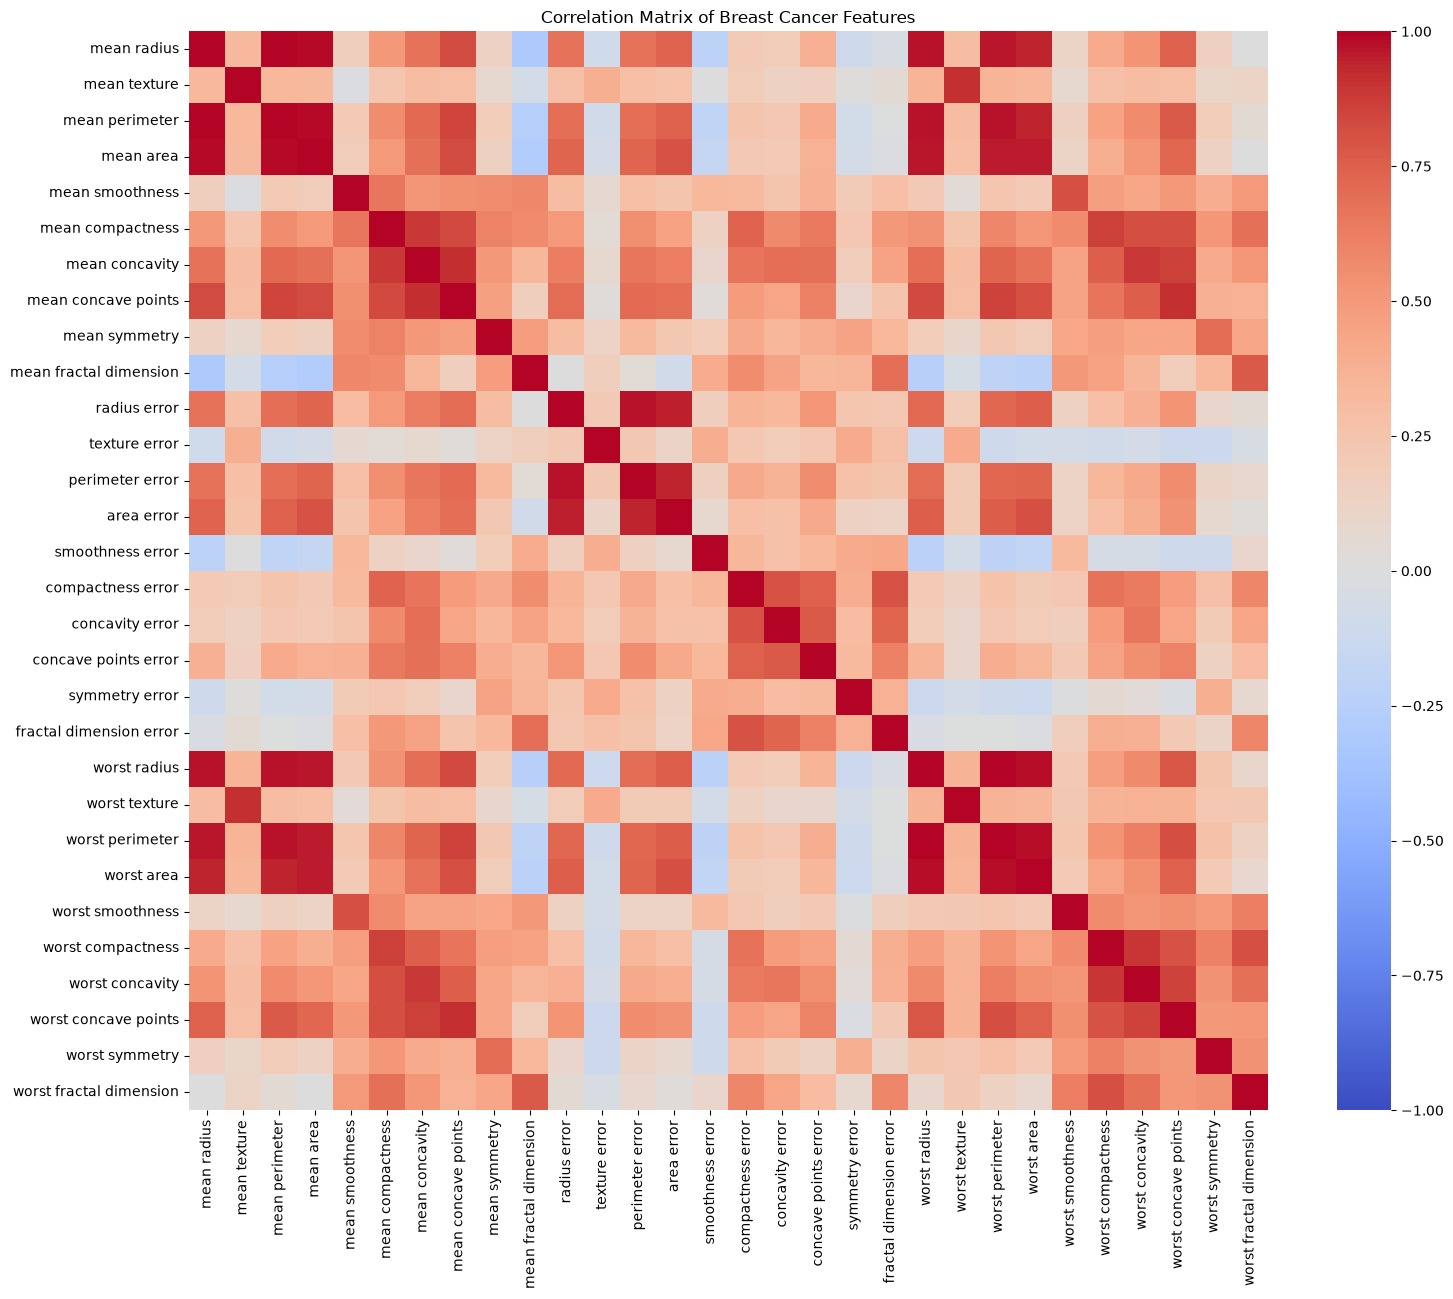

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = X.corr()

plt.figure(figsize=(16, 13))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    xticklabels=True,
    yticklabels=True
)

plt.title("Correlation Matrix of Breast Cancer Features")
plt.tight_layout()
plt.show()


In [13]:

import numpy as np
import pandas as pd

correlation_matrix = X.corr()

# Keep only the upper triangle, excluding the diagonal
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

strongest_pairs = (
    upper_triangle
    .stack()
    .rename("correlation")
    .reset_index()
    .rename(columns={
        "level_0": "feature_1",
        "level_1": "feature_2"
    })
)

strongest_pairs["absolute_correlation"] = (
    strongest_pairs["correlation"].abs()
)

strongest_pairs = strongest_pairs.sort_values(
    "absolute_correlation",
    ascending=False
)

strongest_pairs.head(15).round(3)


,feature_1,feature_2,correlation,absolute_correlation
2,mean radius,mean perimeter,0.998,0.998
622,worst radius,worst perimeter,0.994,0.994
3,mean radius,mean area,0.987,0.987
63,mean perimeter,mean area,0.987,0.987
623,worst radius,worst area,0.984,0.984
683,worst perimeter,worst area,0.978,0.978
312,radius error,perimeter error,0.973,0.973
82,mean perimeter,worst perimeter,0.970,0.970
20,mean radius,worst radius,0.970,0.970
80,mean perimeter,worst radius,0.969,0.969


In [14]:

from sklearn.model_selection import train_test_split

# Encode the target explicitly: malignant = 1, benign = 0
y_binary = (df["diagnosis"] == "malignant").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_binary,
    test_size=0.20,
    stratify=y_binary,
    random_state=42
)

print("Training feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)

print("\nTraining class counts:")
print(y_train.value_counts().rename(index={0: "Benign", 1: "Malignant"}))

print("\nTest class counts:")
print(y_test.value_counts().rename(index={0: "Benign", 1: "Malignant"}))

print("\nTraining class proportions:")
print(
    y_train.value_counts(normalize=True)
    .rename(index={0: "Benign", 1: "Malignant"})
    .round(3)
)

print("\nTest class proportions:")
print(
    y_test.value_counts(normalize=True)
    .rename(index={0: "Benign", 1: "Malignant"})
    .round(3)
)


Training feature shape: (455, 30)
Test feature shape: (114, 30)

Training class counts:
diagnosis
Benign       285
Malignant    170
Name: count, dtype: int64

Test class counts:
diagnosis
Benign       72
Malignant    42
Name: count, dtype: int64

Training class proportions:
diagnosis
Benign       0.626
Malignant    0.374
Name: proportion, dtype: float64

Test class proportions:
diagnosis
Benign       0.632
Malignant    0.368
Name: proportion, dtype: float64


In [15]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

baseline_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "SVC (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ]),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

In [17]:

import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "accuracy": "accuracy"
}

results = []

for name, model in baseline_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    results.append({
        "model": name,
        "mean_roc_auc": scores["test_roc_auc"].mean(),
        "std_roc_auc": scores["test_roc_auc"].std(),
        "mean_average_precision": scores[
            "test_average_precision"
        ].mean(),
        "mean_recall": scores["test_recall"].mean(),
        "mean_precision": scores["test_precision"].mean(),
        "mean_f1": scores["test_f1"].mean(),
        "mean_accuracy": scores["test_accuracy"].mean()
    })

baseline_results = (
    pd.DataFrame(results)
    .sort_values("mean_roc_auc", ascending=False)
    .reset_index(drop=True)
)

baseline_results.round(4)


,model,mean_roc_auc,std_roc_auc,mean_average_precision,mean_recall,mean_precision,mean_f1,mean_accuracy
0,Logistic Regression,0.9958,0.0047,0.9949,0.9529,0.9771,0.9640,0.9736
1,SVC (RBF),0.9949,0.0050,0.9939,0.9471,0.9769,0.9610,0.9714
2,XGBoost,0.9939,0.0044,0.9923,0.9529,0.9704,0.9614,0.9714
3,Random Forest,0.9880,0.0073,0.9865,0.9353,0.9584,0.9461,0.9604


In [18]:

import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "accuracy": "accuracy"
}

detailed_results = []

for name, model in baseline_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    row = {"model": name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std()

    detailed_results.append(row)

detailed_results_df = pd.DataFrame(detailed_results)

detailed_results_df.round(4)


,model,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,recall_mean,recall_std,precision_mean,precision_std,f1_mean,f1_std,accuracy_mean,accuracy_std
0,Logistic Regression,0.9958,0.0047,0.9949,0.0046,0.9529,0.0399,0.9771,0.0280,0.9640,0.0207,0.9736,0.0149
1,Random Forest,0.9880,0.0073,0.9865,0.0074,0.9353,0.0390,0.9584,0.0221,0.9461,0.0226,0.9604,0.0164
2,SVC (RBF),0.9949,0.0050,0.9939,0.0047,0.9471,0.0343,0.9769,0.0210,0.9610,0.0082,0.9714,0.0054
3,XGBoost,0.9939,0.0044,0.9923,0.0043,0.9529,0.0235,0.9704,0.0181,0.9614,0.0154,0.9714,0.0112


In [19]:
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)
from scipy.stats import loguniform

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_distributions = {
    "Logistic Regression": {
        "model__C": loguniform(0.001, 100)
    },
    "SVC (RBF)": {
        "model__C": loguniform(0.01, 100),
        "model__gamma": loguniform(0.0001, 1)
    },
    "Random Forest": {
        "n_estimators": [200, 300, 500],
        "max_depth": [None, 5, 10, 20],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.5]
    },
    "XGBoost": {
        "n_estimators": [100, 200, 300, 500],
        "max_depth": [2, 3, 4, 5],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "subsample": [0.7, 0.9, 1.0],
        "colsample_bytree": [0.7, 0.9, 1.0]
    }
}

search_results = {}

for name, model in baseline_models.items():
    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_distributions[name],
        n_iter=20,
        scoring="roc_auc",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    search.fit(X_train, y_train)
    search_results[name] = search

    print(f"\n{name}")
    print(f"Best CV ROC-AUC: {search.best_score_:.4f}")
    print(f"Best parameters: {search.best_params_}")


Logistic Regression
Best CV ROC-AUC: 0.9958
Best parameters: {'model__C': np.float64(0.9846738873614566)}

Random Forest
Best CV ROC-AUC: 0.9889
Best parameters: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 5}


c:\Users\pc\breast-cancer-classification\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



SVC (RBF)
Best CV ROC-AUC: 0.9954
Best parameters: {'model__C': np.float64(5.456725485601478), 'model__gamma': np.float64(0.005762487216478602)}

XGBoost
Best CV ROC-AUC: 0.9940
Best parameters: {'subsample': 1.0, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.9}


In [20]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Use the leading baseline pipeline.
# Hyperparameter tuning selected C close to 1,
# so the baseline Logistic Regression is a suitable starting point.
candidate = clone(baseline_models["Logistic Regression"])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Each training row receives a probability from a model
# that did not train on that row.
oof_probabilities = cross_val_predict(
    candidate,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Confirm that column 1 represents malignant (class 1).
print("Model classes:", candidate.fit(X_train, y_train).classes_)
print("OOF predictions:", oof_probabilities.shape)
print("Probability range:",
      oof_probabilities.min(),
      oof_probabilities.max())

Model classes: [0 1]
OOF predictions: (455,)
Probability range: 4.6482274026195684e-07 1.0


In [21]:

from sklearn.metrics import confusion_matrix, classification_report

# Use the current default classification threshold
y_oof_pred = (oof_probabilities >= 0.5).astype(int)

# Calculate confusion matrix
cm = confusion_matrix(y_train, y_oof_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)

print(f"\nTrue Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP): {tp}")

print("\nClassification Report:")
print(
    classification_report(
        y_train,
        y_oof_pred,
        labels=[0, 1],
        target_names=["Benign", "Malignant"],
        zero_division=0
    )
)


Confusion Matrix:
[[281   4]
 [  8 162]]

True Negatives (TN): 281
False Positives (FP): 4
False Negatives (FN): 8
True Positives (TP): 162

Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98       285
   Malignant       0.98      0.95      0.96       170

    accuracy                           0.97       455
   macro avg       0.97      0.97      0.97       455
weighted avg       0.97      0.97      0.97       455



In [22]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

threshold_comparison = []

for threshold in np.arange(0.05, 0.96, 0.01):
    y_pred = (oof_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train, y_pred, labels=[0, 1]
    ).ravel()

    threshold_comparison.append({
        "threshold": round(threshold, 2),
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn,
        "recall": tp / (tp + fn) if (tp + fn) else 0,
        "precision": tp / (tp + fp) if (tp + fp) else 0,
        "specificity": tn / (tn + fp) if (tn + fp) else 0
    })

threshold_comparison_df = pd.DataFrame(threshold_comparison)

# Inspect thresholds near the current default of 0.50
threshold_comparison_df[
    threshold_comparison_df["threshold"].between(0.40, 0.60)
].round(4)


,threshold,TP,FN,FP,TN,recall,precision,specificity
35,0.40,164,6,6,279,0.9647,0.9647,0.9789
36,0.41,164,6,6,279,0.9647,0.9647,0.9789
37,0.42,163,7,6,279,0.9588,0.9645,0.9789
38,0.43,163,7,5,280,0.9588,0.9702,0.9825
39,0.44,163,7,5,280,0.9588,0.9702,0.9825
40,0.45,163,7,5,280,0.9588,0.9702,0.9825
41,0.46,163,7,5,280,0.9588,0.9702,0.9825
42,0.47,162,8,4,281,0.9529,0.9759,0.9860
43,0.48,162,8,4,281,0.9529,0.9759,0.9860
44,0.49,162,8,4,281,0.9529,0.9759,0.9860


In [23]:

# Display every candidate threshold, sorted from lowest to highest
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

display(threshold_comparison_df.round(4))


,threshold,TP,FN,FP,TN,recall,precision,specificity
0,0.05,169,1,47,238,0.9941,0.7824,0.8351
1,0.06,169,1,40,245,0.9941,0.8086,0.8596
2,0.07,169,1,35,250,0.9941,0.8284,0.8772
3,0.08,169,1,34,251,0.9941,0.8325,0.8807
4,0.09,169,1,28,257,0.9941,0.8579,0.9018
5,0.10,168,2,27,258,0.9882,0.8615,0.9053
6,0.11,168,2,25,260,0.9882,0.8705,0.9123
7,0.12,168,2,23,262,0.9882,0.8796,0.9193
8,0.13,168,2,23,262,0.9882,0.8796,0.9193
9,0.14,168,2,21,264,0.9882,0.8889,0.9263


In [24]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

# Confirm the training data dimensions
print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

# Confirm class distribution
print("\nTraining class distribution:")
print(
    pd.Series(y_train)
    .map({0: "Benign", 1: "Malignant"})
    .value_counts()
)

# Define reproducible outer and inner CV strategies
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

print("\nOuter CV folds:", outer_cv.get_n_splits(X_train, y_train))
print("Inner CV folds:", inner_cv.get_n_splits(X_train, y_train))


Training features: (455, 30)
Training target: (455,)

Training class distribution:
diagnosis
Benign       285
Malignant    170
Name: count, dtype: int64

Outer CV folds: 5
Inner CV folds: 5


In [25]:

import numpy as np
import pandas as pd

from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import roc_auc_score

from xgboost import XGBClassifier

# Candidate models and search spaces
nested_models = {
    "Logistic Regression": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=5000, random_state=42
            ))
        ]),
        {
            "model__C": loguniform(1e-3, 1e2)
        }
    ),

    "SVC (RBF)": (
        Pipeline([
            ("scaler", StandardScaler()),
            # probability=False is sufficient for ROC-AUC
            ("model", SVC(kernel="rbf", probability=False))
        ]),
        {
            "model__C": loguniform(1e-2, 1e2),
            "model__gamma": loguniform(1e-4, 1e-1)
        }
    ),

    "Random Forest": (
        RandomForestClassifier(
            random_state=42, n_jobs=-1
        ),
        {
            "n_estimators": [200, 300, 500],
            "max_depth": [None, 3, 5, 8, 12],
            "min_samples_leaf": [1, 2, 4],
            "max_features": ["sqrt", "log2", 0.5]
        }
    ),

    "XGBoost": (
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ),
        {
            "n_estimators": [200, 300, 500],
            "max_depth": [2, 3, 4],
            "learning_rate": loguniform(0.01, 0.2),
            "subsample": [0.8, 0.9, 1.0],
            "colsample_bytree": [0.8, 0.9, 1.0]
        }
    )
}

# Evaluate the full tuning procedure using outer folds.
# Hyperparameters are selected only inside each outer training fold.
nested_results = []
nested_best_params = []

for model_name, (estimator, param_space) in nested_models.items():
    print(f"Evaluating: {model_name}")

    for fold, (train_idx, val_idx) in enumerate(
        outer_cv.split(X_train, y_train), start=1
    ):
        X_outer_train = X_train.iloc[train_idx]
        X_outer_val = X_train.iloc[val_idx]

        y_outer_train = y_train.iloc[train_idx]
        y_outer_val = y_train.iloc[val_idx]

        search = RandomizedSearchCV(
            estimator=clone(estimator),
            param_distributions=param_space,
            n_iter=20,
            scoring="roc_auc",
            cv=inner_cv,
            refit=True,
            random_state=42,
            n_jobs=1,
            error_score="raise"
        )

        search.fit(X_outer_train, y_outer_train)

        best_model = search.best_estimator_

        # Use continuous scores to evaluate ranking performance.
        if hasattr(best_model, "predict_proba"):
            outer_scores = best_model.predict_proba(
                X_outer_val
            )[:, 1]
        else:
            outer_scores = best_model.decision_function(
                X_outer_val
            )

        outer_auc = roc_auc_score(y_outer_val, outer_scores)

        nested_results.append({
            "model": model_name,
            "outer_fold": fold,
            "outer_roc_auc": outer_auc,
            "inner_best_roc_auc": search.best_score_
        })

        nested_best_params.append({
            "model": model_name,
            "outer_fold": fold,
            "best_params": search.best_params_
        })

nested_results_df = pd.DataFrame(nested_results)

nested_summary = (
    nested_results_df
    .groupby("model")["outer_roc_auc"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

display(nested_summary.round(4))


Evaluating: Logistic Regression
Evaluating: SVC (RBF)


c:\Users\pc\breast-cancer-classification\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\pc\breast-cancer-classification\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\pc\breast-cancer-classification\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\pc\breast-cancer-classification\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The

Evaluating: Random Forest


c:\Users\pc\breast-cancer-classification\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\pc\breast-cancer-classification\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\pc\breast-cancer-classification\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\pc\breast-cancer-classifi

Evaluating: XGBoost


,mean,std
model,,
SVC (RBF),0.9954,0.0064
Logistic Regression,0.9953,0.0046
XGBoost,0.9939,0.0046
Random Forest,0.9883,0.0072


In [26]:

# Inspect each outer fold's ROC-AUC
fold_scores = nested_results_df.pivot(
    index="outer_fold",
    columns="model",
    values="outer_roc_auc"
)

display(fold_scores.round(4))


model,Logistic Regression,Random Forest,SVC (RBF),XGBoost
outer_fold,,,,
1,0.9948,0.9840,0.9979,0.9979
2,0.9990,1.0000,0.9990,0.9985
3,0.9990,0.9907,0.9990,0.9912
4,0.9876,0.9843,0.9840,0.9876
5,0.9959,0.9827,0.9969,0.9943


In [27]:

import numpy as np
import pandas as pd

from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV
)

# 1. Define the candidate model and search space
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

lr_param_distributions = {
    "model__C": loguniform(1e-3, 1e3)
}

# 2. Set up outer and inner cross-validation
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

# 3. Allocate one OOF probability per training observation
oof_probabilities = np.full(len(y_train), np.nan)

# 4. Tune within each outer training fold
for fold, (train_idx, valid_idx) in enumerate(
    outer_cv.split(X_train, y_train), start=1
):
    X_outer_train = X_train.iloc[train_idx]
    y_outer_train = y_train.iloc[train_idx]

    X_outer_valid = X_train.iloc[valid_idx]

    search = RandomizedSearchCV(
        estimator=clone(lr_pipeline),
        param_distributions=lr_param_distributions,
        n_iter=20,
        scoring="roc_auc",
        cv=inner_cv,
        random_state=42,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_outer_train, y_outer_train)

    # Predict only the observations held out in this outer fold
    oof_probabilities[valid_idx] = (
        search.best_estimator_.predict_proba(X_outer_valid)[:, 1]
    )

    print(
        f"Fold {fold}: "
        f"Best inner ROC-AUC = {search.best_score_:.4f}, "
        f"Best C = {search.best_params_['model__C']:.4f}"
    )

# 5. Verify the OOF predictions
assert not np.isnan(oof_probabilities).any()

print("\nOOF probability shape:", oof_probabilities.shape)
print("Minimum probability:", oof_probabilities.min())
print("Maximum probability:", oof_probabilities.max())
print("All probabilities finite:", np.isfinite(oof_probabilities).all())


Fold 1: Best inner ROC-AUC = 0.9951, Best C = 1.4078
Fold 2: Best inner ROC-AUC = 0.9955, Best C = 0.3905
Fold 3: Best inner ROC-AUC = 0.9923, Best C = 0.0669
Fold 4: Best inner ROC-AUC = 0.9958, Best C = 17.7188
Fold 5: Best inner ROC-AUC = 0.9913, Best C = 0.0559

OOF probability shape: (455,)
Minimum probability: 2.2465527748287154e-12
Maximum probability: 1.0
All probabilities finite: True


In [28]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Ensure the target labels align with the OOF probability array
y_true = np.asarray(y_train)

assert len(y_true) == len(oof_probabilities)

threshold_results = []

for threshold in np.arange(0.05, 0.951, 0.01):
    # Convert probabilities into class predictions
    y_pred = (oof_probabilities >= threshold).astype(int)

    # Confusion matrix order: [[TN, FP], [FN, TP]]
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    recall = tp / (tp + fn) if (tp + fn) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    threshold_results.append({
        "threshold": round(threshold, 2),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "recall": recall,
        "precision": precision,
        "specificity": specificity,
        "F1": f1
    })

threshold_df = pd.DataFrame(threshold_results)

# Show selected thresholds for an initial overview
display(
    threshold_df[
        threshold_df["threshold"].isin(
            [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]
        )
    ].round(4)
)


,threshold,TN,FP,FN,TP,recall,precision,specificity,F1
5,0.1,250,35,2,168,0.9882,0.8276,0.8772,0.9008
15,0.2,267,18,4,166,0.9765,0.9022,0.9368,0.9379
25,0.3,277,8,7,163,0.9588,0.9532,0.9719,0.9560
35,0.4,280,5,7,163,0.9588,0.9702,0.9825,0.9645
45,0.5,283,2,11,159,0.9353,0.9876,0.9930,0.9607
55,0.6,285,0,15,155,0.9118,1.0000,1.0000,0.9538


In [29]:
eligible_thresholds = threshold_df[
    threshold_df["recall"] >= 0.95
].copy()

best_threshold_candidates = eligible_thresholds.sort_values(
    by=["precision", "threshold"],
    ascending=[False, False]
)

display(
    best_threshold_candidates[
        [
            "threshold", "TN", "FP", "FN", "TP",
            "recall", "precision", "specificity", "F1"
        ]
    ].head(10).round(4)
)

,threshold,TN,FP,FN,TP,recall,precision,specificity,F1
35,0.40,280,5,7,163,0.9588,0.9702,0.9825,0.9645
34,0.39,280,5,7,163,0.9588,0.9702,0.9825,0.9645
33,0.38,280,5,7,163,0.9588,0.9702,0.9825,0.9645
36,0.41,280,5,8,162,0.9529,0.9701,0.9825,0.9614
32,0.37,279,6,7,163,0.9588,0.9645,0.9789,0.9617
31,0.36,278,7,7,163,0.9588,0.9588,0.9754,0.9588
30,0.35,278,7,7,163,0.9588,0.9588,0.9754,0.9588
29,0.34,278,7,7,163,0.9588,0.9588,0.9754,0.9588
28,0.33,278,7,7,163,0.9588,0.9588,0.9754,0.9588
22,0.27,277,8,5,165,0.9706,0.9538,0.9719,0.9621


In [30]:

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Cross-validation uses the training split only
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression with all 30 features
all_features_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

all_features_search = GridSearchCV(
    estimator=all_features_pipeline,
    param_grid={"model__C": [0.01, 0.1, 1, 10, 100]},
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

all_features_search.fit(X_train, y_train)

# Logistic Regression with RFE feature selection
rfe_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("feature_selection", RFE(
        estimator=LogisticRegression(
            max_iter=5000,
            random_state=42
        ),
        n_features_to_select=10,
        step=1
    )),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

rfe_search = GridSearchCV(
    estimator=rfe_pipeline,
    param_grid={
        "feature_selection__n_features_to_select": [5, 10, 15, 20, 25, 30],
        "model__C": [0.01, 0.1, 1, 10, 100]
    },
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

rfe_search.fit(X_train, y_train)

# Compare the best cross-validation results
comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression — all features",
        "Best CV ROC-AUC": all_features_search.best_score_,
        "Best parameters": all_features_search.best_params_
    },
    {
        "Model": "Logistic Regression — RFE",
        "Best CV ROC-AUC": rfe_search.best_score_,
        "Best parameters": rfe_search.best_params_
    }
])

display(comparison)


,Model,Best CV ROC-AUC,Best parameters
0,Logistic Regression — all features,0.995769,{'model__C': 1}
1,Logistic Regression — RFE,0.995769,{'feature_selection__n_features_to_select': 30...


In [31]:
print("All-features best parameters:")
print(all_features_search.best_params_)

print("\nRFE best parameters:")
print(rfe_search.best_params_)

print("\nNumber of original features:", X_train.shape[1])

print(
    "Number of features selected by RFE:",
    rfe_search.best_estimator_
    .named_steps["feature_selection"]
    .n_features_to_select
)

All-features best parameters:
{'model__C': 1}

RFE best parameters:
{'feature_selection__n_features_to_select': 30, 'model__C': 1}

Number of original features: 30
Number of features selected by RFE: 30


In [32]:
rfe_results = pd.DataFrame(rfe_search.cv_results_)

feature_count_results = (
    rfe_results
    .groupby("param_feature_selection__n_features_to_select")
    .agg(
        best_mean_cv_roc_auc=("mean_test_score", "max"),
        best_cv_std=("std_test_score", "min")
    )
    .reset_index()
    .rename(columns={
        "param_feature_selection__n_features_to_select": "n_features"
    })
    .sort_values("n_features")
)

display(feature_count_results)

,n_features,best_mean_cv_roc_auc,best_cv_std
0,5,0.995150,0.002998
1,10,0.993602,0.004136
2,15,0.993808,0.004179
3,20,0.995150,0.004174
4,25,0.995666,0.003834
5,30,0.995769,0.003605


In [33]:
# Create an RFE pipeline configured to retain five features
rfe_5_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("feature_selection", RFE(
        estimator=LogisticRegression(
            max_iter=5000,
            random_state=42
        ),
        n_features_to_select=5
    )),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

# Fit using training data only
rfe_5_pipeline.fit(X_train, y_train)

# Identify the selected feature names
selected_mask = (
    rfe_5_pipeline
    .named_steps["feature_selection"]
    .support_
)

selected_features = X_train.columns[selected_mask]

print("Number of selected features:", len(selected_features))
print("\nSelected features:")
print(selected_features.tolist())

Number of selected features: 5

Selected features:
['radius error', 'worst radius', 'worst texture', 'worst area', 'worst concave points']


In [34]:

from sklearn.base import clone
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Model A: all 30 features
all_features_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=1,
        max_iter=5000,
        random_state=42
    ))
])

# Model B: RFE selects 5 features inside each CV fold
rfe_5_model = Pipeline([
    ("scaler", StandardScaler()),
    ("feature_selection", RFE(
        estimator=LogisticRegression(
            max_iter=5000,
            random_state=42
        ),
        n_features_to_select=5
    )),
    ("model", LogisticRegression(
        C=1,
        max_iter=5000,
        random_state=42
    ))
])

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1"
}

results = []

for name, model in [
    ("All 30 features", all_features_model),
    ("RFE — 5 features", rfe_5_model)
]:
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    row = {"Model": name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric.upper()} mean"] = values.mean()
        row[f"{metric.upper()} SD"] = values.std(ddof=1)

    results.append(row)

comparison_results = pd.DataFrame(results)
display(comparison_results.round(4))


,Model,ROC_AUC mean,ROC_AUC SD,AVERAGE_PRECISION mean,AVERAGE_PRECISION SD,RECALL mean,RECALL SD,PRECISION mean,PRECISION SD,F1 mean,F1 SD
0,All 30 features,0.9958,0.0052,0.9949,0.0051,0.9529,0.0446,0.9771,0.0313,0.9640,0.0231
1,RFE — 5 features,0.9951,0.0036,0.9934,0.0038,0.9412,0.0360,0.9766,0.0241,0.9579,0.0135


In [35]:

import numpy as np
from scipy.stats import loguniform

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV
)

# Outer CV generates out-of-fold probabilities
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Inner CV tunes the model within each outer training fold
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

rfe_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("feature_selection", RFE(
        estimator=LogisticRegression(
            max_iter=5000,
            random_state=42
        ),
        n_features_to_select=5,
        step=1
    )),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

param_distributions = {
    "feature_selection__n_features_to_select": [5, 10, 15, 20, 25, 30],
    "model__C": loguniform(1e-3, 1e3)
}

oof_rfe_probabilities = np.full(len(y_train), np.nan)
oof_rfe_fold = np.full(len(y_train), -1)
rfe_fold_results = []

for fold, (train_idx, valid_idx) in enumerate(
    outer_cv.split(X_train, y_train), start=1
):
    X_outer_train = X_train.iloc[train_idx]
    X_outer_valid = X_train.iloc[valid_idx]

    y_outer_train = y_train.iloc[train_idx]

    search = RandomizedSearchCV(
        estimator=clone(rfe_pipeline),
        param_distributions=param_distributions,
        n_iter=20,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        random_state=42 + fold,
        refit=True
    )

    search.fit(X_outer_train, y_outer_train)

    oof_rfe_probabilities[valid_idx] = (
        search.predict_proba(X_outer_valid)[:, 1]
    )
    oof_rfe_fold[valid_idx] = fold

    rfe_fold_results.append({
        "outer_fold": fold,
        "best_inner_roc_auc": search.best_score_,
        "best_n_features": search.best_params_[
            "feature_selection__n_features_to_select"
        ],
        "best_C": search.best_params_["model__C"]
    })

    print(
        f"Fold {fold}: "
        f"inner ROC-AUC={search.best_score_:.4f}, "
        f"features={search.best_params_['feature_selection__n_features_to_select']}, "
        f"C={search.best_params_['model__C']:.4f}"
    )

assert np.isfinite(oof_rfe_probabilities).all()
assert (oof_rfe_fold != -1).all()

print("\nOOF probability shape:", oof_rfe_probabilities.shape)
print("All probabilities finite:", np.isfinite(oof_rfe_probabilities).all())

display(pd.DataFrame(rfe_fold_results))


Fold 1: inner ROC-AUC=0.9946, features=15, C=0.6437
Fold 2: inner ROC-AUC=0.9955, features=25, C=0.3938
Fold 3: inner ROC-AUC=0.9936, features=5, C=737.0223
Fold 4: inner ROC-AUC=0.9950, features=30, C=0.1937
Fold 5: inner ROC-AUC=0.9902, features=5, C=0.1708

OOF probability shape: (455,)
All probabilities finite: True


,outer_fold,best_inner_roc_auc,best_n_features,best_C
0,1,0.994632,15,0.643710
1,2,0.995468,25,0.393777
2,3,0.993609,5,737.022267
3,4,0.994976,30,0.193660
4,5,0.990226,5,0.170758


In [36]:

import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix

y_true = np.asarray(y_train).astype(int)
thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)

threshold_rows = []

for threshold in thresholds:
    y_pred = (oof_rfe_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    recall = tp / (tp + fn) if (tp + fn) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    threshold_rows.append({
        "threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "recall": recall,
        "precision": precision,
        "specificity": specificity,
        "F1": f1
    })

threshold_df_rfe = pd.DataFrame(threshold_rows)

eligible_rfe = threshold_df_rfe[
    threshold_df_rfe["recall"] >= 0.95
].sort_values(
    ["precision", "threshold"],
    ascending=[False, False]
)

print("Number of thresholds meeting recall >= 0.95:",
      len(eligible_rfe))

display(eligible_rfe.head(10))


Number of thresholds meeting recall >= 0.95: 38


,threshold,TN,FP,FN,TP,recall,precision,specificity,F1
37,0.38,278,7,7,163,0.958824,0.958824,0.975439,0.958824
36,0.37,276,9,7,163,0.958824,0.947674,0.968421,0.953216
35,0.36,275,10,6,164,0.964706,0.942529,0.964912,0.953488
34,0.35,275,10,6,164,0.964706,0.942529,0.964912,0.953488
33,0.34,275,10,6,164,0.964706,0.942529,0.964912,0.953488
32,0.33,275,10,6,164,0.964706,0.942529,0.964912,0.953488
31,0.32,275,10,6,164,0.964706,0.942529,0.964912,0.953488
30,0.31,274,11,6,164,0.964706,0.937143,0.961404,0.950725
29,0.30,272,13,6,164,0.964706,0.926554,0.954386,0.945245
28,0.29,271,14,6,164,0.964706,0.921348,0.950877,0.942529


In [37]:

# Show the best eligible thresholds, including all ties at the top
best_precision = eligible_rfe["precision"].max()

top_ties = eligible_rfe[
    np.isclose(eligible_rfe["precision"], best_precision)
].sort_values("threshold", ascending=False)

display(top_ties)

print("Best eligible precision:", best_precision)
print("Highest threshold among precision ties:",
      top_ties.iloc[0]["threshold"])


,threshold,TN,FP,FN,TP,recall,precision,specificity,F1
37,0.38,278,7,7,163,0.958824,0.958824,0.975439,0.958824


Best eligible precision: 0.9588235294117647
Highest threshold among precision ties: 0.38


In [38]:

import numpy as np
import pandas as pd

from scipy.stats import loguniform
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

all_features_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

param_distributions = {
    "model__C": loguniform(1e-3, 1e3)
}

oof_all_probabilities = np.full(len(y_train), np.nan)
all_fold_results = []

for fold, (train_idx, valid_idx) in enumerate(
    outer_cv.split(X_train, y_train), start=1
):
    X_outer_train = X_train.iloc[train_idx]
    X_outer_valid = X_train.iloc[valid_idx]
    y_outer_train = y_train.iloc[train_idx]

    search = RandomizedSearchCV(
        estimator=all_features_pipeline,
        param_distributions=param_distributions,
        n_iter=20,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        random_state=42 + fold,
        refit=True
    )

    search.fit(X_outer_train, y_outer_train)

    oof_all_probabilities[valid_idx] = (
        search.predict_proba(X_outer_valid)[:, 1]
    )

    all_fold_results.append({
        "outer_fold": fold,
        "best_inner_roc_auc": search.best_score_,
        "best_C": search.best_params_["model__C"]
    })

    print(
        f"Fold {fold}: "
        f"inner ROC-AUC={search.best_score_:.4f}, "
        f"C={search.best_params_['model__C']:.4f}"
    )

assert np.isfinite(oof_all_probabilities).all()

print("\nOOF probability shape:", oof_all_probabilities.shape)
print("All probabilities finite:",
      np.isfinite(oof_all_probabilities).all())

display(pd.DataFrame(all_fold_results))


Fold 1: inner ROC-AUC=0.9953, C=1.7659
Fold 2: inner ROC-AUC=0.9953, C=0.2305
Fold 3: inner ROC-AUC=0.9922, C=0.0488
Fold 4: inner ROC-AUC=0.9955, C=6.4417
Fold 5: inner ROC-AUC=0.9915, C=0.0858

OOF probability shape: (455,)
All probabilities finite: True


,outer_fold,best_inner_roc_auc,best_C
0,1,0.995270,1.765929
1,2,0.995307,0.230503
2,3,0.992159,0.048830
3,4,0.995450,6.441726
4,5,0.991493,0.085753


In [39]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

y_true = np.asarray(y_train).astype(int)
thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)

all_threshold_rows = []

for threshold in thresholds:
    y_pred = (oof_all_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    recall = tp / (tp + fn) if (tp + fn) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    all_threshold_rows.append({
        "threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "recall": recall,
        "precision": precision,
        "specificity": specificity,
        "F1": f1
    })

threshold_df_all = pd.DataFrame(all_threshold_rows)

eligible_all = threshold_df_all[
    threshold_df_all["recall"] >= 0.95
].sort_values(
    ["precision", "threshold"],
    ascending=[False, False]
)

print("Eligible thresholds:", len(eligible_all))
display(eligible_all.head(10))

best_precision_all = eligible_all["precision"].max()
best_all_ties = eligible_all[
    np.isclose(eligible_all["precision"], best_precision_all)
].sort_values("threshold", ascending=False)

print("\nBest eligible precision:", best_precision_all)
print("Selected threshold:", best_all_ties.iloc[0]["threshold"])
display(best_all_ties)


Eligible thresholds: 40


,threshold,TN,FP,FN,TP,recall,precision,specificity,F1
39,0.40,280,5,8,162,0.952941,0.970060,0.982456,0.961424
38,0.39,280,5,8,162,0.952941,0.970060,0.982456,0.961424
37,0.38,279,6,7,163,0.958824,0.964497,0.978947,0.961652
36,0.37,279,6,7,163,0.958824,0.964497,0.978947,0.961652
35,0.36,278,7,7,163,0.958824,0.958824,0.975439,0.958824
34,0.35,278,7,7,163,0.958824,0.958824,0.975439,0.958824
33,0.34,278,7,7,163,0.958824,0.958824,0.975439,0.958824
32,0.33,278,7,7,163,0.958824,0.958824,0.975439,0.958824
29,0.30,277,8,5,165,0.970588,0.953757,0.971930,0.962099
28,0.29,277,8,5,165,0.970588,0.953757,0.971930,0.962099



Best eligible precision: 0.9700598802395209
Selected threshold: 0.4


,threshold,TN,FP,FN,TP,recall,precision,specificity,F1
39,0.40,280,5,8,162,0.952941,0.97006,0.982456,0.961424
38,0.39,280,5,8,162,0.952941,0.97006,0.982456,0.961424


In [44]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Keep the selected decision threshold fixed
FINAL_THRESHOLD = 0.40

# Define the selected model
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=1,
        max_iter=5000,
        random_state=42
    ))
])

# Fit on the complete training split only
final_model.fit(X_train, y_train)

print("Training completed.")
print("Training observations:", len(X_train))
print("Number of features:", X_train.shape[1])
print("Decision threshold:", FINAL_THRESHOLD)
print("Positive class: malignant (1)")


Training completed.
Training observations: 455
Number of features: 30
Decision threshold: 0.4
Positive class: malignant (1)


In [45]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Predict probabilities for the positive class: malignant (1)
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply the previously selected threshold without changing it
test_predictions = (
    test_probabilities >= FINAL_THRESHOLD
).astype(int)

# Confusion matrix: rows = actual, columns = predicted
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

print("Confusion matrix (rows: actual; columns: predicted)")
print("                 Predicted benign  Predicted malignant")
print(f"Actual benign         {cm[0, 0]:>5}              {cm[0, 1]:>5}")
print(f"Actual malignant      {cm[1, 0]:>5}              {cm[1, 1]:>5}")

# Final test metrics
test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Malignant recall": recall_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Specificity": cm[0, 0] / (cm[0, 0] + cm[0, 1]),
    "F1": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Average precision": average_precision_score(
        y_test, test_probabilities
    )
})

print("\nFinal test metrics:")
display(test_metrics.to_frame("Score").round(4))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Benign", "Malignant"],
    zero_division=0
))


Confusion matrix (rows: actual; columns: predicted)
                 Predicted benign  Predicted malignant
Actual benign            71                  1
Actual malignant          2                 40

Final test metrics:


,Score
Accuracy,0.9737
Malignant recall,0.9524
Precision,0.9756
Specificity,0.9861
F1,0.9639
ROC-AUC,0.9960
Average precision,0.9943



Classification report:
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        72
   Malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [46]:
import sys
import xgboost

print("Python executable:", sys.executable)
print("XGBoost version:", xgboost.__version__)

Python executable: c:\Users\pc\breast-cancer-classification\.venv\Scripts\python.exe
XGBoost version: 3.4.1


In [47]:
import pandas as pd
import numpy as np

# Use the existing final model and held-out test data
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply the already selected threshold
test_predictions = (test_probabilities >= FINAL_THRESHOLD).astype(int)

# Identify misclassified observations
errors = np.asarray(test_predictions) != np.asarray(y_test)

error_analysis = pd.DataFrame({
    "actual_diagnosis": np.asarray(y_test),
    "predicted_diagnosis": np.asarray(test_predictions),
    "malignant_probability": test_probabilities,
    "correct_prediction": ~errors
}, index=X_test.index)

# Display only the misclassified observations
misclassified = error_analysis.loc[errors].copy()

misclassified["actual_diagnosis"] = (
    misclassified["actual_diagnosis"]
    .map({0: "Benign", 1: "Malignant"})
)

misclassified["predicted_diagnosis"] = (
    misclassified["predicted_diagnosis"]
    .map({0: "Benign", 1: "Malignant"})
)

misclassified["error_type"] = np.where(
    misclassified["actual_diagnosis"] == "Malignant",
    "False negative",
    "False positive"
)

misclassified

,actual_diagnosis,predicted_diagnosis,malignant_probability,correct_prediction,error_type
455,Benign,Malignant,0.509155,False,False positive
73,Malignant,Benign,0.061429,False,False negative
190,Malignant,Benign,0.314532,False,False negative


In [48]:
features_to_inspect = [
    "worst radius",
    "worst area",
    "worst concave points",
    "mean concave points"
]

# Combine the selected features with actual outcomes and predictions
error_feature_analysis = X_test.loc[
    misclassified.index, features_to_inspect
].copy()

error_feature_analysis["actual_diagnosis"] = (
    y_test.loc[misclassified.index]
    .map({0: "Benign", 1: "Malignant"})
)

error_feature_analysis["predicted_diagnosis"] = (
    test_predictions[
        X_test.index.get_indexer(misclassified.index)
    ]
)

error_feature_analysis["malignant_probability"] = (
    test_probabilities[
        X_test.index.get_indexer(misclassified.index)
    ]
)

error_feature_analysis

,worst radius,worst area,worst concave points,mean concave points,actual_diagnosis,predicted_diagnosis,malignant_probability
455,15.05,705.6,0.07763,0.03264,Benign,1,0.509155
73,16.57,812.4,0.13830,0.05069,Malignant,0,0.061429
190,15.74,762.4,0.17720,0.06618,Malignant,0,0.314532


In [49]:
features_to_inspect = [
    "worst radius",
    "worst area",
    "worst concave points",
    "mean concave points"
]

# Summarize features by actual diagnosis in the test set
group_medians = X_test.assign(
    diagnosis=y_test.map({0: "Benign", 1: "Malignant"})
).groupby("diagnosis")[features_to_inspect].median().T

print("Median feature values by actual diagnosis:")
display(group_medians)

print("Misclassified observations:")
display(error_feature_analysis)

Median feature values by actual diagnosis:


diagnosis,Benign,Malignant
worst radius,13.335000,20.07500
worst area,538.200000,1248.50000
worst concave points,0.075970,0.17565
mean concave points,0.023815,0.08057


Misclassified observations:


,worst radius,worst area,worst concave points,mean concave points,actual_diagnosis,predicted_diagnosis,malignant_probability
455,15.05,705.6,0.07763,0.03264,Benign,1,0.509155
73,16.57,812.4,0.13830,0.05069,Malignant,0,0.061429
190,15.74,762.4,0.17720,0.06618,Malignant,0,0.314532
